In [10]:
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mplhep as hep
import gc 

In [11]:
df_2el2mu = pd.read_parquet("df_2mu2el_datos_filtrados.parquet")
df_2el2mu_higgs = pd.read_parquet("df_2mu2el_higgs_filtrados.parquet")
df_2el2mu_zz = pd.read_parquet("df_2mu2el_zz_filtrados.parquet")

print("Número de eventos  listos para procesar:", len(df_2el2mu))
print("Número de eventos  (Higgs MC):", len(df_2el2mu_higgs))
print("Número de eventos (ZZ MC):", len(df_2el2mu_zz))

Número de eventos  listos para procesar: 467
Número de eventos  (Higgs MC): 24965
Número de eventos (ZZ MC): 163295


In [28]:
# Ver las columnas de tus DataFrames de muones  
print("Columnas en df_2el2mu:", df_2el2mu.columns.tolist())
print("Columnas en df_4mu_higgs:", df_2el2mu_higgs.columns.tolist())
print("Columnas en df_4mu_zz:", df_2el2mu_zz.columns.tolist())

Columnas en df_2el2mu: ['run', 'luminosityBlock', 'event', 'pt_mu1', 'eta_mu1', 'phi_mu1', 'charge_mu1', 'iso_mu1', 'dxy_mu1', 'dz_mu1', 'dxyErr_mu1', 'dzErr_mu1', 'pt_mu2', 'eta_mu2', 'phi_mu2', 'charge_mu2', 'iso_mu2', 'dxy_mu2', 'dz_mu2', 'dxyErr_mu2', 'dzErr_mu2', 'pt_el1', 'eta_el1', 'phi_el1', 'charge_el1', 'iso_el1', 'dxy_el1', 'dz_el1', 'dxyErr_el1', 'dzErr_el1', 'pt_el2', 'eta_el2', 'phi_el2', 'charge_el2', 'iso_el2', 'dxy_el2', 'dz_el2', 'dxyErr_el2', 'dzErr_el2', 'sip3d_mu1', 'sip3d_mu2', 'sip3d_el1', 'sip3d_el2']
Columnas en df_4mu_higgs: ['run', 'luminosityBlock', 'event', 'pt_mu1', 'eta_mu1', 'phi_mu1', 'charge_mu1', 'iso_mu1', 'dxy_mu1', 'dz_mu1', 'dxyErr_mu1', 'dzErr_mu1', 'pt_mu2', 'eta_mu2', 'phi_mu2', 'charge_mu2', 'iso_mu2', 'dxy_mu2', 'dz_mu2', 'dxyErr_mu2', 'dzErr_mu2', 'pt_el1', 'eta_el1', 'phi_el1', 'charge_el1', 'iso_el1', 'dxy_el1', 'dz_el1', 'dxyErr_el1', 'dzErr_el1', 'pt_el2', 'eta_el2', 'phi_el2', 'charge_el2', 'iso_el2', 'dxy_el2', 'dz_el2', 'dxyErr_el2', 

In [30]:
# Quitamos valores negativos como los valores centinela ( -999) de las columnas de iso_mu1, iso_mu2, iso_el1, iso_el2

def solo_positivos(df): 
    mask_positivo = (df["iso_mu1"] >= 0) & (df["iso_mu2"] >= 0) & (df["iso_el1"] >= 0) & (df["iso_el2"] >= 0)
    return df[mask_positivo].copy()

# Aplicamos y guardamos el filtro de forma independiente para cada DataFrame
df_2el2mu  = solo_positivos(df_2el2mu)
df_2el2mu_higgs = solo_positivos(df_2el2mu_higgs)
df_2el2mu_zz   = solo_positivos(df_2el2mu_zz)

# Verificación final de los conteos limpios
print("Datos reales listos (sin -999):", len(df_2el2mu))
print("Higgs MC listo (sin -999):     ", len(df_2el2mu_higgs))
print("ZZ MC listo (sin -999):        ", len(df_2el2mu_zz))


Datos reales listos (sin -999): 467
Higgs MC listo (sin -999):      24965
ZZ MC listo (sin -999):         163295


In [14]:
# Comprobar si son el mismo objeto en memoria
print("¿Son el mismo DataFrame en memoria?", df_2el2mu is df_2el2mu_higgs)
# Verificamos los valores mínimos de aislamiento en los datos limpios
print("Mínimos de aislamiento (Datos):\n", df_2el2mu[["iso_mu1", "iso_mu2", "iso_el1", "iso_el2"]].min())

¿Son el mismo DataFrame en memoria? False
Mínimos de aislamiento (Datos):
 iso_mu1    0.0
iso_mu2    0.0
iso_el1    0.0
iso_el2    0.0
dtype: float32


In [31]:
# Tabla de Flujo de Cortes para Canal 2e2mu

# Calcular sip3d solo para los 2 muones y 2 electrones
for prefix in ["mu1", "mu2", "el1", "el2"]:
    ip3d = np.sqrt(df_2el2mu[f"dxy_{prefix}"] ** 2 + df_2el2mu[f"dz_{prefix}"] ** 2)
    sig = np.sqrt(df_2el2mu[f"dxyErr_{prefix}"] ** 2 + df_2el2mu[f"dzErr_{prefix}"] ** 2)
    df_2el2mu[f"sip3d_{prefix}"] = ip3d / sig

# Definición de máscaras para el canal mixto (2 muones, 2 electrones)

mask_pt = (df_2el2mu ["pt_mu1"] > 5) & (df_2el2mu ["pt_mu2"] > 5) & (df_2el2mu ["pt_el1"] > 7) & (df_2el2mu ["pt_el2"] > 7)
mask_eta = (df_2el2mu ["eta_mu1"].abs() < 2.4) & (df_2el2mu ["eta_mu2"].abs() < 2.4) & (df_2el2mu ["eta_el1"].abs() < 2.5) & (df_2el2mu ["eta_el2"].abs() < 2.5)
mask_iso = (df_2el2mu ["iso_mu1"] < 0.40) & (df_2el2mu ["iso_mu2"] < 0.40) & (df_2el2mu ["iso_el1"] < 0.40) & (df_2el2mu ["iso_el2"] < 0.40)
mask_sip = (df_2el2mu ["sip3d_mu1"] < 4) & (df_2el2mu ["sip3d_mu2"] < 4) & (df_2el2mu ["sip3d_el1"] < 4) & (df_2el2mu ["sip3d_el2"] < 4)
mask_dxy = (df_2el2mu ["dxy_mu1"].abs() < 0.5) & (df_2el2mu ["dxy_mu2"].abs() < 0.5) & (df_2el2mu ["dxy_el1"].abs() < 0.5) & (df_2el2mu ["dxy_el2"].abs() < 0.5)
mask_dz  = (df_2el2mu ["dz_mu1"].abs() < 1.0)  & (df_2el2mu ["dz_mu2"].abs() < 1.0)  & (df_2el2mu ["dz_el1"].abs() < 1.0)  & (df_2el2mu ["dz_el2"].abs() < 1.0)

# DataFrame final usando filtros

df_final = df_2el2mu [mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz].copy()

n_total = len(df_2el2mu )
n_pt = len(df_2el2mu [mask_pt])
n_eta = len(df_2el2mu [mask_pt & mask_eta])
n_iso = len(df_2el2mu [mask_pt & mask_eta & mask_iso])
n_sip = len(df_2el2mu [mask_pt & mask_eta & mask_iso & mask_sip])
n_dxy_dz = len(df_2el2mu[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz])

data_flujo = {
    "Corte aplicado": [
        "Sin filtros (2e2mu)",
        "pT Líderes (>5, 7 GeV)",
        "Aceptancia Detector (|eta| < 2.5)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4",
        "Parámetro impacto dxy<0.5, dz<1.0 (Final)",
    ],
    "Eventos Restantes": [n_total, n_pt, n_eta, n_iso, n_sip, n_dxy_dz],
    "Aceptancia (%)": [
        100.0,
        (n_pt / n_total) * 100,
        (n_eta / n_total) * 100,
        (n_iso / n_total) * 100,
        (n_sip / n_total) * 100,
        (n_dxy_dz / n_total) * 100,
    ],
}
tabla_flujo = pd.DataFrame(data_flujo)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 2e2mu - Datos Reales)")
print(tabla_flujo)

#  Mismo proceso, para el Higgs MC (df_2el2mu_higgs) 
for prefix in ["mu1", "mu2", "el1", "el2"]:
    ip3d_h = np.sqrt(df_2el2mu_higgs[f"dxy_{prefix}"] ** 2 + df_2el2mu_higgs[f"dz_{prefix}"] ** 2)
    sig_h  = np.sqrt(df_2el2mu_higgs[f"dxyErr_{prefix}"] ** 2 + df_2el2mu_higgs[f"dzErr_{prefix}"] ** 2)
    df_2el2mu_higgs[f"sip3d_{prefix}"] = ip3d_h / sig_h
mask_pt_h  = (df_2el2mu_higgs["pt_mu1"] > 5) & (df_2el2mu_higgs["pt_mu2"] > 5) & (df_2el2mu_higgs["pt_el1"] > 7) & (df_2el2mu_higgs["pt_el2"] > 7)
mask_eta_h = (df_2el2mu_higgs["eta_mu1"].abs() < 2.4) & (df_2el2mu_higgs["eta_mu2"].abs() < 2.4) & (df_2el2mu_higgs["eta_el1"].abs() < 2.5) & (df_2el2mu_higgs["eta_el2"].abs() < 2.5)
mask_iso_h = (df_2el2mu_higgs["iso_mu1"] < 0.40) & (df_2el2mu_higgs["iso_mu2"] < 0.40) & (df_2el2mu_higgs["iso_el1"] < 0.40) & (df_2el2mu_higgs["iso_el2"] < 0.40)
mask_sip_h = (df_2el2mu_higgs["sip3d_mu1"] < 4) & (df_2el2mu_higgs["sip3d_mu2"] < 4) & (df_2el2mu_higgs["sip3d_el1"] < 4) & (df_2el2mu_higgs["sip3d_el2"] < 4)
mask_dxy_h = (df_2el2mu_higgs["dxy_mu1"].abs() < 0.5) & (df_2el2mu_higgs["dxy_mu2"].abs() < 0.5) & (df_2el2mu_higgs["dxy_el1"].abs() < 0.5) & (df_2el2mu_higgs["dxy_el2"].abs() < 0.5)
mask_dz_h  = (df_2el2mu_higgs["dz_mu1"].abs() < 1.0)  & (df_2el2mu_higgs["dz_mu2"].abs() < 1.0)  & (df_2el2mu_higgs["dz_el1"].abs() < 1.0)  & (df_2el2mu_higgs["dz_el2"].abs() < 1.0)

df_final_higgs = df_2el2mu_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h & mask_dxy_h & mask_dz_h].copy()
print("\nEventos de Higgs después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz):", len(df_final_higgs))

# Mismo proceso, para el fondo ZZ MC (df_2el2mu_zz)
for prefix in ["mu1", "mu2", "el1", "el2"]:
    ip3d_zz = np.sqrt(df_2el2mu_zz[f"dxy_{prefix}"] ** 2 + df_2el2mu_zz[f"dz_{prefix}"] ** 2)
    sig_zz  = np.sqrt(df_2el2mu_zz[f"dxyErr_{prefix}"] ** 2 + df_2el2mu_zz[f"dzErr_{prefix}"] ** 2)
    df_2el2mu_zz[f"sip3d_{prefix}"] = ip3d_zz / sig_zz
mask_pt_zz  = (df_2el2mu_zz["pt_mu1"] > 5) & (df_2el2mu_zz["pt_mu2"] > 5) & (df_2el2mu_zz["pt_el1"] > 7) & (df_2el2mu_zz["pt_el2"] > 7)
mask_eta_zz = (df_2el2mu_zz["eta_mu1"].abs() < 2.4) & (df_2el2mu_zz["eta_mu2"].abs() < 2.4) & (df_2el2mu_zz["eta_el1"].abs() < 2.5) & (df_2el2mu_zz["eta_el2"].abs() < 2.5)
mask_iso_zz = (df_2el2mu_zz["iso_mu1"] < 0.40) & (df_2el2mu_zz["iso_mu2"] < 0.40) & (df_2el2mu_zz["iso_el1"] < 0.40) & (df_2el2mu_zz["iso_el2"] < 0.40)
mask_sip_zz = (df_2el2mu_zz["sip3d_mu1"] < 4) & (df_2el2mu_zz["sip3d_mu2"] < 4) & (df_2el2mu_zz["sip3d_el1"] < 4) & (df_2el2mu_zz["sip3d_el2"] < 4)
mask_dxy_zz = (df_2el2mu_zz["dxy_mu1"].abs() < 0.5) & (df_2el2mu_zz["dxy_mu2"].abs() < 0.5) & (df_2el2mu_zz["dxy_el1"].abs() < 0.5) & (df_2el2mu_zz["dxy_el2"].abs() < 0.5)
mask_dz_zz  = (df_2el2mu_zz["dz_mu1"].abs() < 1.0)  & (df_2el2mu_zz["dz_mu2"].abs() < 1.0)  & (df_2el2mu_zz["dz_el1"].abs() < 1.0)  & (df_2el2mu_zz["dz_el2"].abs() < 1.0)

df_final_zz = df_2el2mu_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz & mask_dxy_zz & mask_dz_zz].copy()
print("\nEventos de ZZ después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz):", len(df_final_zz))


Tabla de Flujo de Cortes (Canal H -> ZZ* -> 2e2mu - Datos Reales)
                              Corte aplicado  Eventos Restantes  \
0                        Sin filtros (2e2mu)                467   
1                     pT Líderes (>5, 7 GeV)                398   
2          Aceptancia Detector (|eta| < 2.5)                397   
3                     Aislamiento iso < 0.40                100   
4                Parámetro impacto sip3d < 4                 85   
5  Parámetro impacto dxy<0.5, dz<1.0 (Final)                 84   

   Aceptancia (%)  
0      100.000000  
1       85.224839  
2       85.010707  
3       21.413276  
4       18.201285  
5       17.987152  

Eventos de Higgs después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz): 13231

Eventos de ZZ después de cortes de calidad (pt/eta/iso/sip3d/dxy/dz): 79876


In [32]:
print("Columnas en df_2el2mu:", df_2el2mu.columns.tolist())
print("Columnas en df_2el2mu_higgs:", df_2el2mu_higgs.columns.tolist())
print("Columnas en df_2el2mu_zz:", df_2el2mu_zz.columns.tolist())

Columnas en df_2el2mu: ['run', 'luminosityBlock', 'event', 'pt_mu1', 'eta_mu1', 'phi_mu1', 'charge_mu1', 'iso_mu1', 'dxy_mu1', 'dz_mu1', 'dxyErr_mu1', 'dzErr_mu1', 'pt_mu2', 'eta_mu2', 'phi_mu2', 'charge_mu2', 'iso_mu2', 'dxy_mu2', 'dz_mu2', 'dxyErr_mu2', 'dzErr_mu2', 'pt_el1', 'eta_el1', 'phi_el1', 'charge_el1', 'iso_el1', 'dxy_el1', 'dz_el1', 'dxyErr_el1', 'dzErr_el1', 'pt_el2', 'eta_el2', 'phi_el2', 'charge_el2', 'iso_el2', 'dxy_el2', 'dz_el2', 'dxyErr_el2', 'dzErr_el2', 'sip3d_mu1', 'sip3d_mu2', 'sip3d_el1', 'sip3d_el2']
Columnas en df_2el2mu_higgs: ['run', 'luminosityBlock', 'event', 'pt_mu1', 'eta_mu1', 'phi_mu1', 'charge_mu1', 'iso_mu1', 'dxy_mu1', 'dz_mu1', 'dxyErr_mu1', 'dzErr_mu1', 'pt_mu2', 'eta_mu2', 'phi_mu2', 'charge_mu2', 'iso_mu2', 'dxy_mu2', 'dz_mu2', 'dxyErr_mu2', 'dzErr_mu2', 'pt_el1', 'eta_el1', 'phi_el1', 'charge_el1', 'iso_el1', 'dxy_el1', 'dz_el1', 'dxyErr_el1', 'dzErr_el1', 'pt_el2', 'eta_el2', 'phi_el2', 'charge_el2', 'iso_el2', 'dxy_el2', 'dz_el2', 'dxyErr_el2

In [34]:
# Constantes físicas para electrones (masa en GeV)
M_Muon = 0.10566
M_Electron = 0.000511
Z_Mass_Nominal = 91.1876


# Función para calcular ΔR 

def delta_r(eta1, phi1, eta2, phi2):
    d_eta = eta1 - eta2
    d_phi = np.arctan2(np.sin(phi1 - phi2), np.cos(phi1 - phi2))
    return np.sqrt(d_eta**2 + d_phi**2)

def get_particula_vars(df, idx): #Define la función que recibe dos cosas: el DataFrame con los datos (df) y un número entero (idx) que representa la partícula que queremos evaluar (del 1 al 4).
    # Traduce los índices 1,2,3,4 a los nombres reales de las columnas del canal 2e2mu
    p = {1: "mu1", 2: "mu2", 3: "el1", 4: "el2"}[idx]
    m = M_Electron if "el" in p else M_Muon # Evalúa el texto almacenado en p. Si la etiqueta contiene las letras "el", le asigna la masa del electrón (M_Electron = $0.000511\text{ GeV}$). Si no (porque es "mu"), le asigna la masa del muón (M_Muon = 0.10566GeV)
    return (
        df[f"pt_{p}"], 
        df[f"eta_{p}"], 
        df[f"phi_{p}"], 
        df.get(f"charge_{p}", 0), 
        m
    )

def masa_par_mixto (df, i, j):
    pt_i, eta_i, phi_i, _, m_i = get_particula_vars(df, i)
    pt_j, eta_j, phi_j, _, m_j = get_particula_vars(df, j)

    px = pt_i * np.cos(phi_i) + pt_j * np.cos(phi_j)
    py = pt_i * np.sin(phi_i) + pt_j * np.sin(phi_j)
    pz = pt_i * np.sinh(eta_i) + pt_j * np.sinh(eta_j)

    E = np.sqrt(pt_i**2 + pt_i**2 * np.sinh(eta_i)**2 + m_i**2) + \
        np.sqrt(pt_j**2 + pt_j**2 * np.sinh(eta_j)**2 + m_j**2)
    
    return np.sqrt(np.maximum(0.0, E**2 - (px**2 + py**2 + pz**2)))


# Identificación directa de Z1 y Z2
def identificar_Z_onoff_mixto(df):

    pares = [((1, 2), (3, 4)), ((1, 3), (2, 4)), ((1, 4), (2, 3))]

    mejor_mZ1 = np.full(len(df), np.nan)
    mejor_mZ2 = np.full(len(df), np.nan)
    mejor_diff = np.full(len(df), np.inf)
    mejor_dr_valido = np.full(len(df), False)

    mejor_idx_a = np.zeros(len(df), dtype=int)
    mejor_idx_b = np.zeros(len(df), dtype=int)
    mejor_idx_c = np.zeros(len(df), dtype=int)
    mejor_idx_d = np.zeros(len(df), dtype=int)

    for (a, b), (c, d) in pares:

        _, _, _, charge_a, _ = get_particula_vars(df, a)
        _, _, _, charge_b, _ = get_particula_vars(df, b)
        _, _, _, charge_c, _ = get_particula_vars(df, c)
        _, _, _, charge_d, _ = get_particula_vars(df, d)

        valido = (charge_a + charge_b == 0) & (charge_c + charge_d == 0)

        _, eta_a, phi_a, _, _ = get_particula_vars(df, a)
        _, eta_b, phi_b, _, _ = get_particula_vars(df, b)
        _, eta_c, phi_c, _, _ = get_particula_vars(df, c)
        _, eta_d, phi_d, _, _ = get_particula_vars(df, d)

        # ΔR de este par específico 

        dr_ab = delta_r(eta_a, phi_a, eta_b, phi_b)
        dr_cd = delta_r(eta_c, phi_c, eta_d, phi_d)
        dr_par = (dr_ab > 0.02) & (dr_cd > 0.02)

        m_ab = masa_par_mixto(df, a, b)
        m_cd = masa_par_mixto(df, c, d)

        ab_es_z1 = np.abs(m_ab - Z_Mass_Nominal) < np.abs(m_cd - Z_Mass_Nominal)
        m1 = np.where(ab_es_z1, m_ab, m_cd)
        m2 = np.where(ab_es_z1, m_cd, m_ab)
        idx_a = np.where(ab_es_z1, a, c)
        idx_b = np.where(ab_es_z1, b, d)
        idx_c = np.where(ab_es_z1, c, a)
        idx_d = np.where(ab_es_z1, d, b)

        # Elección de "mejor" combinación (masa/carga)
         
        diff = np.abs(m1 - Z_Mass_Nominal)
        mask = valido & (diff < mejor_diff)

        mejor_mZ1 = np.where(mask, m1, mejor_mZ1)
        mejor_mZ2 = np.where(mask, m2, mejor_mZ2)
        mejor_diff = np.where(mask, diff, mejor_diff)
        mejor_dr_valido = np.where(mask, dr_par, mejor_dr_valido)
        
        # Se guarda el ΔR de la combinación que ganó 

        mejor_idx_a = np.where(mask, idx_a, mejor_idx_a)
        mejor_idx_b = np.where(mask, idx_b, mejor_idx_b)
        mejor_idx_c = np.where(mask, idx_c, mejor_idx_c)
        mejor_idx_d = np.where(mask, idx_d, mejor_idx_d)

        # Ahora (después de elegir), se aplica el ΔR como filtro final

    valido_final = ~np.isnan(mejor_mZ1) & mejor_dr_valido 
    df = df.copy()
    df["mZ1"] = np.where(valido_final, mejor_mZ1, np.nan)
    df["mZ2"] = np.where(valido_final, mejor_mZ2, np.nan)

    df["mejor_idx_a"] = mejor_idx_a
    df["mejor_idx_b"] = mejor_idx_b
    df["mejor_idx_c"] = mejor_idx_c
    df["mejor_idx_d"] = mejor_idx_d
    
    return df


# Datos Reales

df_final = identificar_Z_onoff_mixto(df_final)

print("Eventos con mZ1 = NaN (invalidados por ΔR):", df_final["mZ1"].isna().sum())
print(df_final[["mZ1", "mZ2"]].describe())

# Aplicar los cortes de masa del skim

df_final = df_final[
    (df_final["mZ1"] > 40) & (df_final["mZ1"] < 120) &
    (df_final["mZ2"] > 12) & (df_final["mZ2"] < 120)
].copy()

print("Eventos después del skim de masa (Datos 2e2mu):", len(df_final))

# HIGGS MC 
df_final_higgs = identificar_Z_onoff_mixto(df_final_higgs)
print("\nHiggs MC (2e2mu):")
print("Eventos con mZ1 = NaN (invalidados por ΔR):", df_final_higgs["mZ1"].isna().sum())
print(df_final_higgs[["mZ1", "mZ2"]].describe())

df_final_higgs = df_final_higgs[
    (df_final_higgs["mZ1"] > 40) & (df_final_higgs["mZ1"] < 120) &
    (df_final_higgs["mZ2"] > 12) & (df_final_higgs["mZ2"] < 120)
].copy()
print("Eventos después del skim de masa (Higgs):", len(df_final_higgs))

# ZZ MC 
df_final_zz = identificar_Z_onoff_mixto(df_final_zz)
print("\nZZ MC (2e2mu):")
print("Eventos con mZ1 = NaN (invalidados por ΔR):", df_final_zz["mZ1"].isna().sum())
print(df_final_zz[["mZ1", "mZ2"]].describe())

df_final_zz = df_final_zz[
    (df_final_zz["mZ1"] > 40) & (df_final_zz["mZ1"] < 120) &
    (df_final_zz["mZ2"] > 12) & (df_final_zz["mZ2"] < 120)
].copy()
print("Eventos después del skim de masa (ZZ):", len(df_final_zz))

Eventos con mZ1 = NaN (invalidados por ΔR): 8
              mZ1         mZ2
count   76.000000   76.000000
mean    83.708578   63.451462
std     14.781141   43.483569
min     41.695419    0.356818
25%     84.308416   19.880920
50%     90.643318   86.808109
75%     91.782185   92.517433
max    105.521324  202.939789
Eventos después del skim de masa (Datos 2e2mu): 59

Higgs MC (2e2mu):
Eventos con mZ1 = NaN (invalidados por ΔR): 125
                mZ1           mZ2
count  13106.000000  13106.000000
mean      83.845225     27.154676
std       11.301164     10.837599
min       18.902117      0.493859
25%       79.075504     20.065870
50%       88.412872     27.007854
75%       91.362486     32.567890
max      111.167175     74.692848
Eventos después del skim de masa (Higgs): 12008

ZZ MC (2e2mu):
Eventos con mZ1 = NaN (invalidados por ΔR): 1177
                mZ1           mZ2
count  78699.000000  78699.000000
mean      79.775060     56.356941
std       17.399954     47.628819
min        

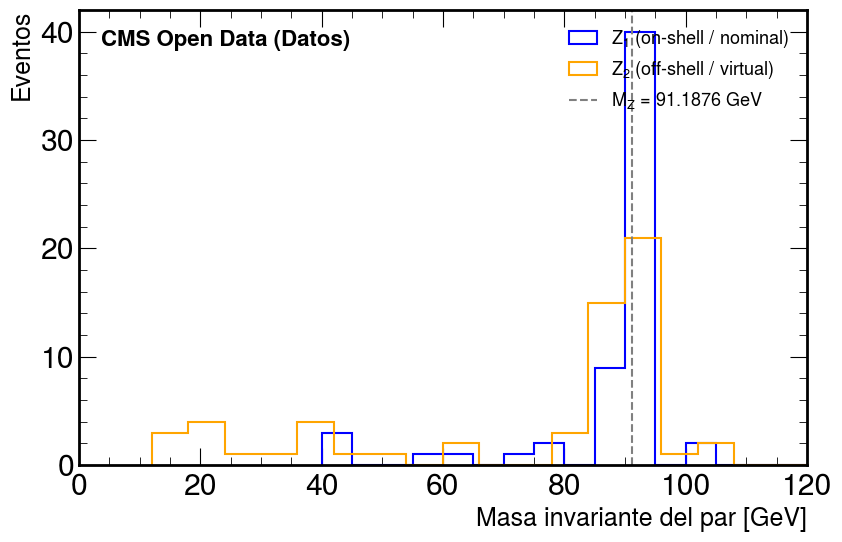

<Figure size 1000x1000 with 0 Axes>

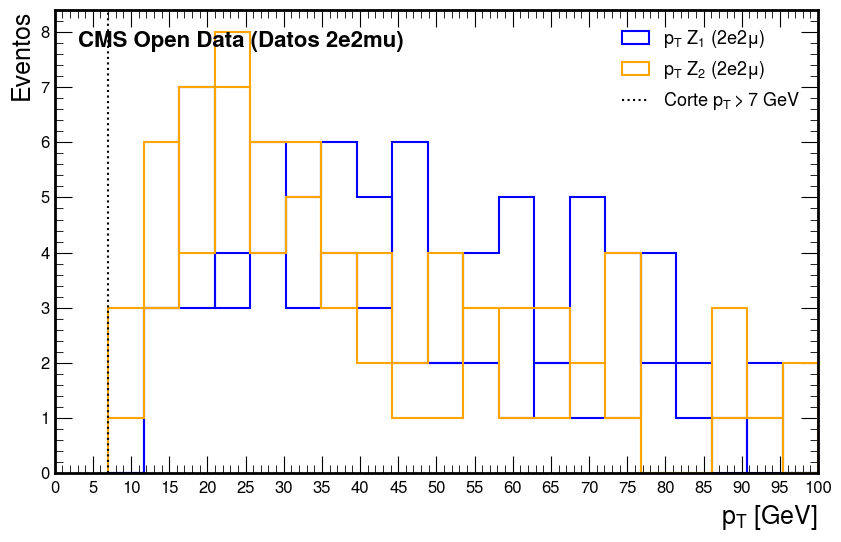

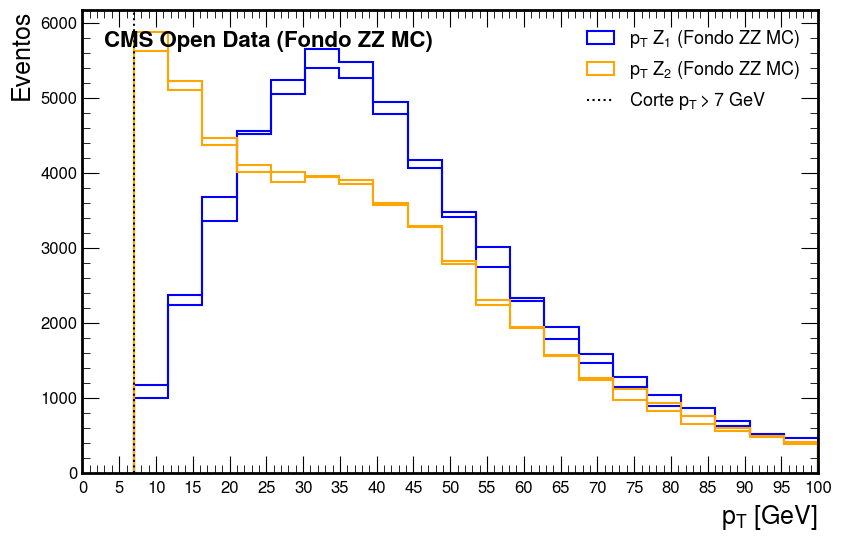

In [35]:
#  Gráfica: Masa invariante de los pares Z1 y Z2 (Canal 2e2mu)
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final["mZ1"],
    bins=16,
    range=(40, 120),
    histtype="step",
    color="blue",
    linewidth=1.5,
    label=r"$Z_1$ (on-shell / nominal)",
)
ax.hist(
    df_final["mZ2"],
    bins=18,
    range=(12, 120),
    histtype="step",
    color="orange",
    linewidth=1.5,
    label=r"$Z_2$ (off-shell / virtual)",
)
ax.axvline(
    Z_Mass_Nominal,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=r"$M_Z$ = " + str(Z_Mass_Nominal) + r" GeV",
)

ax.set_xlabel(r"Masa invariante del par [GeV]", fontsize=18)
ax.set_ylabel(r"Eventos", fontsize=18)
ax.set_xlim(0, 120)

ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

# Gráfica: pT de las 4 partículas individuales (2 muones + 2 electrones)

columnas_pt = ["pt_mu1", "pt_mu2", "pt_el1", "pt_el2"]
etiquetas_part = ["muón 1", "muón 2", "electrón 1", "electrón 2"]
colores = ["blue", "dodgerblue", "red", "indianred"]

for col, etiq, color in zip(columnas_pt, etiquetas_part, colores):
    ax.hist(
        df_final[col],
        bins=20,
        range=(7, 100),
        histtype="step",
        color=color,
        linewidth=1.5,
        label=r"$p_T$ " + etiq,
    )

ax.axvline(7, color="black", linestyle=":", linewidth=1.5, label=r"Corte $p_T > 7$ GeV")
ax.set_xlabel(r"$p_T$ [GeV]", fontsize=18)
ax.set_ylabel(r"Eventos", fontsize=18) 
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))
ax.text(
    0.03,
    0.92,
    r"CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()


# Extraer el pT de los electrones que forman Z1 y Z2 (Canal 2e2mu)
todos_indices = {1, 2, 3, 4}

mapa_cols_pt = {1: "pt_mu1", 2: "pt_mu2", 3: "pt_el1", 4: "pt_el2"}

def extraer_pt_z_mixto(df):
    pt_Z1_a = np.zeros(len(df))
    pt_Z1_b = np.zeros(len(df))
    
    # Extraemos usando mejor_idx_a y mejor_idx_b que genera tu función de identificación
    idx_a_arr = df["mejor_idx_a"].astype(int).to_numpy()
    idx_b_arr = df["mejor_idx_b"].astype(int).to_numpy()
    
    # Matriz con los pT de las 4 partículas: [mu1, mu2, el1, el2]
    pt_matrix = df[["pt_mu1", "pt_mu2", "pt_el1", "pt_el2"]].to_numpy()
    
    pt_Z2_a = np.zeros(len(df))
    pt_Z2_b = np.zeros(len(df))
    
    for idx in range(len(df)):
        ia = idx_a_arr[idx]
        ib = idx_b_arr[idx]
        
        # pT del par Z1
        if ia > 0:
            pt_Z1_a[idx] = pt_matrix[idx, ia - 1]
        if ib > 0:
            pt_Z1_b[idx] = pt_matrix[idx, ib - 1]
            
        usados = {ia, ib}
        restantes = sorted(todos_indices - usados)
        if len(restantes) == 2:
            pt_Z2_a[idx] = pt_matrix[idx, restantes[0] - 1]
            pt_Z2_b[idx] = pt_matrix[idx, restantes[1] - 1]
            
    df = df.copy()
    df["pt_Z1a"] = pt_Z1_a
    df["pt_Z1b"] = pt_Z1_b
    df["pt_Z2a"] = pt_Z2_a
    df["pt_Z2b"] = pt_Z2_b
    return df

# Aplicamos la extracción a Datos Reales y a ZZ MC
df_final = extraer_pt_z_mixto(df_final)
df_final_zz = extraer_pt_z_mixto(df_final_zz)

# Gráfica: pT de las partículas de Z1 y Z2 para Datos Reales (2e2mu)

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(df_final["pt_Z1a"], bins=20, range=(7, 100), histtype="step", color="blue", linewidth=1.5, label=r"$p_T$ $Z_1$ ($2e2\mu$)")
ax.hist(df_final["pt_Z1b"], bins=20, range=(7, 100), histtype="step", color="blue", linewidth=1.5)
ax.hist(df_final["pt_Z2a"], bins=20, range=(7, 100), histtype="step", color="orange", linewidth=1.5, label=r"$p_T$ $Z_2$ ($2e2\mu$)")
ax.hist(df_final["pt_Z2b"], bins=20, range=(7, 100), histtype="step", color="orange", linewidth=1.5)

ax.axvline(7, color="black", linestyle=":", linewidth=1.5, label=r"Corte $p_T > 7$ GeV")
ax.set_xlabel(r"$p_T$ [GeV]", fontsize=18)
ax.set_ylabel(r"Eventos", fontsize=18)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))
ax.tick_params(axis='both', labelsize=12)
ax.text(0.03, 0.92, r"CMS Open Data (Datos 2e2mu)", transform=ax.transAxes, fontsize=16, fontweight="bold")
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

# Gráfica: pT de las partículas de Z1 y Z2 para Fondo ZZ MC (2e2mu)

fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(df_final_zz["pt_Z1a"], bins=20, range=(7, 100), histtype="step", color="blue", linewidth=1.5, label=r"$p_T$ $Z_1$ (Fondo ZZ MC)")
ax.hist(df_final_zz["pt_Z1b"], bins=20, range=(7, 100), histtype="step", color="blue", linewidth=1.5)
ax.hist(df_final_zz["pt_Z2a"], bins=20, range=(7, 100), histtype="step", color="orange", linewidth=1.5, label=r"$p_T$ $Z_2$ (Fondo ZZ MC)")
ax.hist(df_final_zz["pt_Z2b"], bins=20, range=(7, 100), histtype="step", color="orange", linewidth=1.5)

ax.axvline(7, color="black", linestyle=":", linewidth=1.5, label=r"Corte $p_T > 7$ GeV")
ax.set_xlabel(r"$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))
ax.tick_params(axis='both', labelsize=12)
ax.text(0.03, 0.92, "CMS Open Data (Fondo ZZ MC)", transform=ax.transAxes, fontsize=16, fontweight="bold")
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

Datos filtrado: 60
Higgs filtrado: 12008
ZZ filtrado: 55923


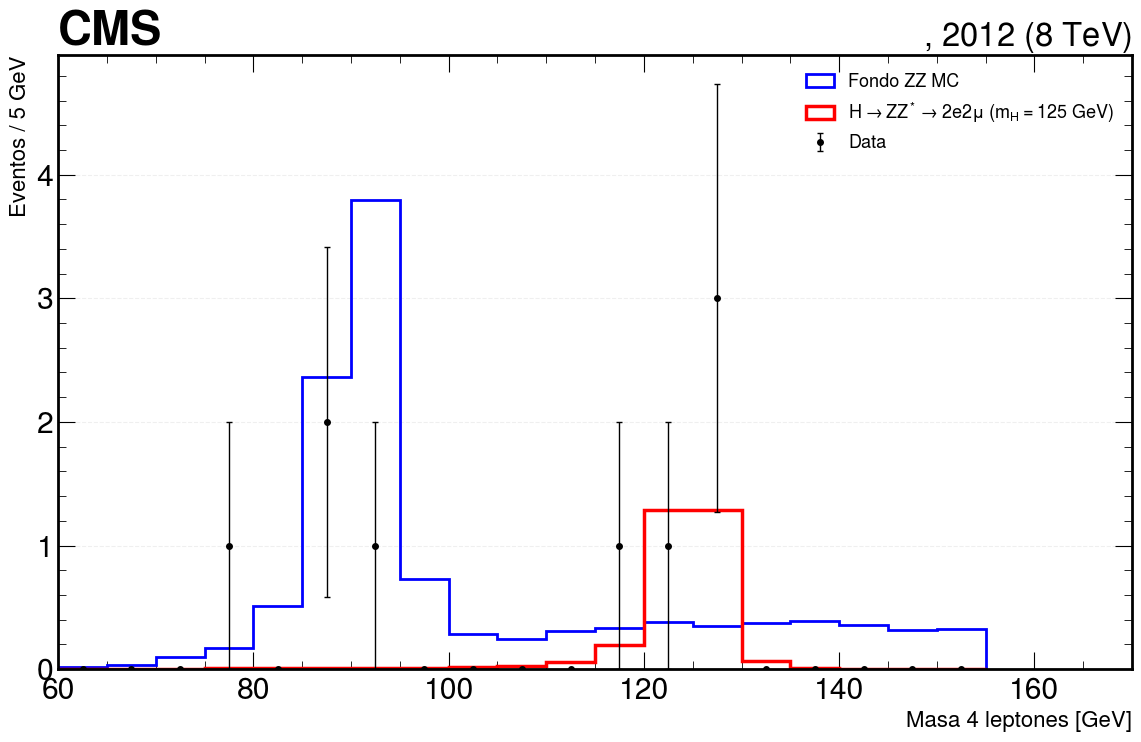

In [43]:
# Estilo CMS
hep.style.use("CMS")

# Parámetros Físicos para electrones

m_mu = 0.105658  # Masa del muón [GeV/c²]
m_e = 0.000511  # Masa del electrón [GeV/c²]
Z_Mass_Nominal = 91.1876

# Función auxiliar para calcular Delta R (respetando periodicidad en phi)
def delta_r(eta1, phi1, eta2, phi2):
    d_eta = eta1 - eta2
    d_phi = np.arctan2(np.sin(phi1 - phi2), np.cos(phi1 - phi2))
    return np.sqrt(d_eta**2 + d_phi**2)

# Función para obtener las variables de cada partícula en el canal mixto
def get_col_name(var, i):
    if i in [1, 2]:
        return f"{var}_mu{i}"
    else:
        el_idx = i - 2 
        return f"{var}_el{el_idx}"

# Función de masa para un par en el canal mixto

def masa_par_mixto(df, i, j):
    es_muon_i = i in [1, 2]
    es_muon_j = j in [1, 2]
    mi = m_mu if es_muon_i else m_e
    mj = m_mu if es_muon_j else m_e

    pt_i = df[get_col_name("pt", i)]
    eta_i = df[get_col_name("eta", i)]
    phi_i = df[get_col_name("phi", i)]
    
    pt_j = df[get_col_name("pt", j)]
    eta_j = df[get_col_name("eta", j)]
    phi_j = df[get_col_name("phi", j)]

    px = pt_i * np.cos(phi_i) + pt_j * np.cos(phi_j)
    py = pt_i * np.sin(phi_i) + pt_j * np.sin(phi_j)
    pz = pt_i * np.sinh(eta_i) + pt_j * np.sinh(eta_j)

    Ei = np.sqrt(pt_i**2 * (1.0 + np.sinh(eta_i)**2) + mi**2)
    Ej = np.sqrt(pt_j**2 * (1.0 + np.sinh(eta_j)**2) + mj**2)
    E = Ei + Ej

    return np.sqrt(np.maximum(0.0, E**2 - (px**2 + py**2 + pz**2)))

# Identificación de Z1 y Z2 para el canal mixto
def identificar_Z_onoff_mixto(df):
    pares = [((1, 2), (3, 4)), ((1, 3), (2, 4)), ((1, 4), (2, 3))]

    mejor_mZ1 = np.full(len(df), np.nan)
    mejor_mZ2 = np.full(len(df), np.nan)
    mejor_diff = np.full(len(df), np.inf)
    mejor_dr_valido = np.full(len(df), False)

    for (a, b), (c, d) in pares:
        charge_a = df[get_col_name("charge", a)]
        charge_b = df[get_col_name("charge", b)]
        charge_c = df[get_col_name("charge", c)]
        charge_d = df[get_col_name("charge", d)]

        valido_carga = (charge_a + charge_b == 0) & (charge_c + charge_d == 0)
        
        # Filtro angular Delta R para evitar solapamientos en ambos pares
        dr_ab = delta_r(df[get_col_name("eta", a)], df[get_col_name("phi", a)], df[get_col_name("eta", b)], df[get_col_name("phi", b)])
        dr_cd = delta_r(df[get_col_name("eta", c)], df[get_col_name("phi", c)], df[get_col_name("eta", d)], df[get_col_name("phi", d)])
        dr_par = (dr_ab > 0.02) & (dr_cd > 0.02)
       
        m_ab = masa_par_mixto(df, a, b)
        m_cd = masa_par_mixto(df, c, d)

        ab_es_z1 = np.abs(m_ab - Z_Mass_Nominal) < np.abs(m_cd - Z_Mass_Nominal)
        m1 = np.where(ab_es_z1, m_ab, m_cd)
        m2 = np.where(ab_es_z1, m_cd, m_ab)

        diff = np.abs(m1 - Z_Mass_Nominal)
        mask = valido_carga & dr_par & (diff < mejor_diff)
        mask = valido_carga & dr_par & (diff < mejor_diff)
        
        mejor_mZ1 = np.where(mask, m1, mejor_mZ1)
        mejor_mZ2 = np.where(mask, m2, mejor_mZ2)
        mejor_diff = np.where(mask, diff, mejor_diff)
        mejor_dr_valido = np.where(mask, dr_par, mejor_dr_valido)   

    valido_final = ~np.isnan(mejor_mZ1) & mejor_dr_valido    

    df = df.copy()
    df["mZ1"] = np.where(valido_final, mejor_mZ1, np.nan)
    df["mZ2"] = np.where(valido_final, mejor_mZ2, np.nan)
    return df

# Reconstrucción del 4-vector del sistema de 4 electrones
def calcular_masa_mixto(df):
    px = 0; py = 0; pz = 0; E = 0
    for i in range(1, 5):
        es_muon = i in [1, 2]
        m_i = m_mu if es_muon else m_e
        pt_i = df[get_col_name("pt", i)]
        eta_i = df[get_col_name("eta", i)]
        phi_i = df[get_col_name("phi", i)]
        
        pxi = pt_i * np.cos(phi_i)
        pyi = pt_i * np.sin(phi_i)
        pzi = pt_i * np.sinh(eta_i)
        Ei  = np.sqrt(pt_i**2 * (1.0 + np.sinh(eta_i)**2) + m_i**2)
        
        px += pxi; py += pyi; pz += pzi; E += Ei
        
    return np.sqrt(np.maximum(0, E**2 - (px**2 + py**2 + pz**2)))


# Procesamiento de los tres datasets (Datos, Higgs, ZZ)
datasets = {
    "Datos": df_2el2mu,
    "Higgs": df_2el2mu_higgs,
    "ZZ": df_2el2mu_zz
}

dfs_filtrados = {}

for nombre, df in datasets.items():
    df = df.copy()
    # Calcular sip3d
    for i in range(1, 5):
        if i in [1, 2]:
            prefix = "mu"
            idx = i
        else:
            prefix = "el"
            idx = i - 2

        ip3d = np.sqrt(df[f"dxy_{prefix}{idx}"] ** 2 + df[f"dz_{prefix}{idx}"] ** 2)
        sig = np.sqrt(
            df[f"dxyErr_{prefix}{idx}"] ** 2 + df[f"dzErr_{prefix}{idx}"] ** 2
        )
        df[f"sip3d_{prefix}{idx}"] = ip3d / sig

    # Máscaras de selección cinemática y de calidad
    mask_pt = (df["pt_mu1"] > 5) & (df["pt_mu2"] > 5) & (df["pt_el1"] > 7) & (df["pt_el2"] > 7)
    mask_eta = (df["eta_mu1"].abs() < 2.4) & (df["eta_mu2"].abs() < 2.4) & (df["eta_el1"].abs() < 2.5) & (df["eta_el2"].abs() < 2.5)
    mask_iso = (df["iso_mu1"] >= 0) & (df["iso_mu1"] < 0.40) & (df["iso_mu2"] >= 0) & (df["iso_mu2"] < 0.40) & (df["iso_el1"] >= 0) & (df["iso_el1"] < 0.40) & (df["iso_el2"] >= 0) & (df["iso_el2"] < 0.40)
    mask_sip = (df["sip3d_mu1"] < 4) & (df["sip3d_mu2"] < 4) & (df["sip3d_el1"] < 4) & (df["sip3d_el2"] < 4)
    mask_dxy = (df["dxy_mu1"].abs() < 0.5) & (df["dxy_mu2"].abs() < 0.5) & (df["dxy_el1"].abs() < 0.5) & (df["dxy_el2"].abs() < 0.5)
    mask_dz = (df["dz_mu1"].abs() < 1.0) & (df["dz_mu2"].abs() < 1.0) & (df["dz_el1"].abs() < 1.0) & (df["dz_el2"].abs() < 1.0)

    df_f = df[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz].copy()
    df_f = identificar_Z_onoff_mixto(df_f)
    df_f = df_f[(df_f["mZ1"] > 40) & (df_f["mZ1"] < 120) & (df_f["mZ2"] > 12) & (df_f["mZ2"] < 120)].copy()
    df_f["M"] = calcular_masa_mixto(df_f)
    
    dfs_filtrados[nombre] = df_f
    print(f"{nombre} filtrado:", len(df_f))

df_data_f = dfs_filtrados["Datos"]
df_higgs_f = dfs_filtrados["Higgs"]
df_zz_f = dfs_filtrados["ZZ"]

# Pesos oficiales del CERN
lumi = 11.46 * 1000
w_higgs = (0.0065 * lumi) / 299973.0
w_zz = (0.077 * 1.386 * lumi) / 1499093.0

# Gráfico unificado con Datos, Higgs y Fondo ZZ MC
mis_bins = np.arange(60, 160, 5)

plt.figure(figsize=(12, 8))

plt.hist(
    df_zz_f["M"],
    bins=mis_bins,
    weights=np.full(len(df_zz_f), w_zz),
    label="Fondo ZZ MC",
    color="blue",
    histtype="step",
    linewidth=2,
)

plt.hist(
    df_higgs_f["M"],
    bins=mis_bins,
    weights=np.full(len(df_higgs_f), w_higgs),
    label=r"$H \to ZZ^* \to 2e2\mu$ ($m_H = 125$ GeV)",
    color="red",
    histtype="step",
    linewidth=2.5,
)

counts, bin_edges = np.histogram(df_data_f["M"], bins=mis_bins)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
plt.errorbar(
    bin_centers,
    counts,
    yerr=np.sqrt(counts),
    fmt="o",
    color="black",
    markersize=4,
    capsize=2,
    elinewidth=1,
    linestyle="none",
    label="Data",
)

ax = plt.gca()
hep.cms.label(data=True, year="2012", com=8, label="Open Data", ax=ax)
plt.xlabel("Masa 4 leptones [GeV]", fontsize=16)
plt.ylabel("Eventos / 5 GeV", fontsize=16)
plt.xlim(60, 170)

plt.legend(loc="upper right", frameon=False, fontsize=13)
plt.grid(axis="y", alpha=0.2, linestyle="--")
plt.tight_layout()
plt.show()

In [44]:
# Guardar los DataFrames filtrados del canal mixto (2e2mu)
df_data_f.to_parquet("df_data_2el2mu.parquet")
df_higgs_f.to_parquet("df_higgs_2el2mu.parquet")
df_zz_f.to_parquet("df_zz_2el2mu.parquet")

print("¡DataFrames del canal mixto guardados exitosamente como parquet!")

¡DataFrames del canal mixto guardados exitosamente como parquet!
